# Section 1 — Direction Fields and Autonomous ODEs

[← Module 3](README.md) · [Next: Euler's Method →](02_euler_method.ipynb)

A first-order ODE

$$
\frac{dy}{dt}=f(t,y)
$$

tells us the slope of a solution curve at every point. A **direction field** displays those slopes before we solve the equation.

In this notebook we focus on the autonomous equation

$$
y'=y-y^3=y(1-y)(1+y).
$$

### Learning goals

By the end, you should be able to:

- read a direction field;
- recognize an autonomous ODE $y'=f(y)$;
- find equilibrium solutions from $f(y)=0$;
- classify equilibria as stable or unstable;
- interpret basins of attraction and connect them to stable/unstable manifolds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def f(t, y):
    """Autonomous ODE y' = y - y^3."""
    return y - y**3

## 1. Build the direction field

At each point $(t,y)$, the ODE gives a slope $y'=f(y)$. Because this equation is autonomous, the slope depends only on $y$, so every horizontal row has the same slope.

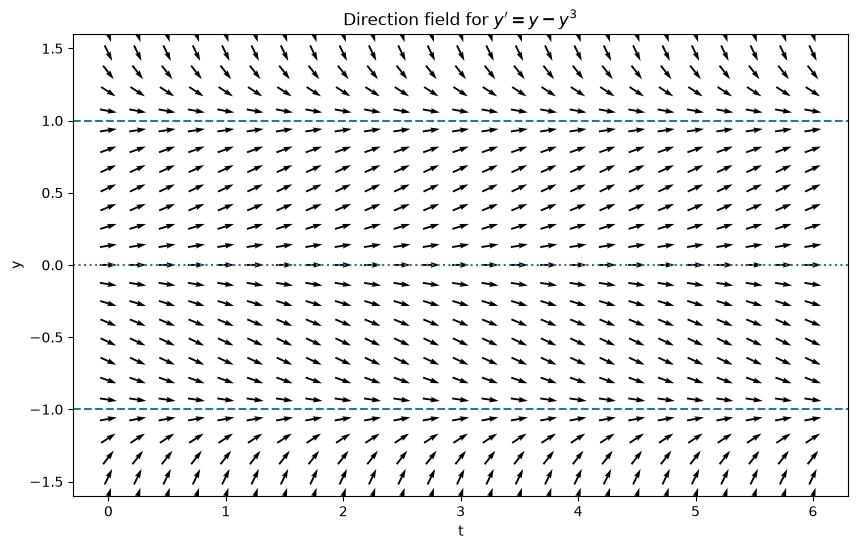

In [2]:
t = np.linspace(0, 6, 25)
y = np.linspace(-1.6, 1.6, 25)
T, Y = np.meshgrid(t, y)
S = f(T, Y)

# Normalize each direction vector so the arrows have comparable lengths.
length = np.sqrt(1 + S**2)
U = 1 / length
V = S / length

fig, ax = plt.subplots(figsize=(10, 6))
ax.quiver(T, Y, U, V, angles="xy", pivot="mid")

for equilibrium, style in [(-1, "--"), (0, ":"), (1, "--")]:
    ax.axhline(equilibrium, linestyle=style, linewidth=1.5)

ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title(r"Direction field for $y'=y-y^3$")
ax.set_ylim(-1.6, 1.6)
plt.show()

## 2. Equilibria and the phase line

For an autonomous ODE $y'=f(y)$, an equilibrium is a constant solution $y=c$ satisfying

$$
f(c)=0.
$$

Here,

$$
y-y^3=y(1-y)(1+y)=0,
$$

so the equilibria are

$$
y=-1,\qquad y=0,\qquad y=1.
$$

The sign of $f(y)$ tells us whether solutions move upward or downward.

In [3]:
equilibria = [-1, 0, 1]
interval_tests = [-1.3, -0.5, 0.5, 1.3]

for y_test in interval_tests:
    direction = "up" if f(0, y_test) > 0 else "down"
    message = (
        f"At y = {y_test:4.1f}, f(y) = {f(0, y_test): .3f}: "
        f"solutions move {direction}."
    )
    print(message)

At y = -1.3, f(y) =  0.897: solutions move up.
At y = -0.5, f(y) = -0.375: solutions move down.
At y =  0.5, f(y) =  0.375: solutions move up.
At y =  1.3, f(y) = -0.897: solutions move down.


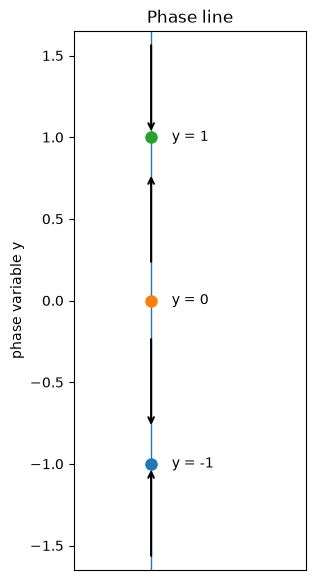

In [4]:
fig, ax = plt.subplots(figsize=(3, 7))
ax.axvline(0, linewidth=1)

for c in equilibria:
    ax.plot(0, c, "o", markersize=8)
    ax.text(0.08, c, f"y = {c}", va="center")

for a, b in [(-1.55, -1.05), (-0.95, -0.05), (0.05, 0.95), (1.05, 1.55)]:
    mid = (a + b) / 2
    dy = 0.28 if f(0, mid) > 0 else -0.28
    ax.annotate("", xy=(0, mid + dy), xytext=(0, mid - dy),
                arrowprops={"arrowstyle": "->", "linewidth": 1.5})

ax.set_ylim(-1.65, 1.65)
ax.set_xlim(-0.3, 0.6)
ax.set_xticks([])
ax.set_ylabel("phase variable y")
ax.set_title("Phase line")
plt.show()

## 3. Stable and unstable equilibria

The phase line already gives the classification:

- $y=-1$: arrows point toward the equilibrium from both sides → **stable**;
- $y=0$: arrows point away on both sides → **unstable**;
- $y=1$: arrows point toward the equilibrium from both sides → **stable**.

For a one-dimensional autonomous equation, we can also check the derivative $f'(c)$. If $f'(c)<0$, the equilibrium is locally attracting; if $f'(c)>0$, it is locally repelling.

Here $f'(y)=1-3y^2$, so $f'(\pm1)=-2<0$ and $f'(0)=1>0$.

In [5]:
def fp(y):
    return 1 - 3 * y**2


for c in equilibria:
    kind = "stable" if fp(c) < 0 else "unstable"
    print(f"y = {c:2d}: f'(y) = {fp(c): .1f}  ->  {kind}")

y = -1: f'(y) = -2.0  ->  stable
y =  0: f'(y) =  1.0  ->  unstable
y =  1: f'(y) = -2.0  ->  stable


## 4. Follow several solution curves

The direction field predicts the long-term behavior. We use a numerical solver here only to draw representative trajectories; in the next sections we build numerical methods ourselves.

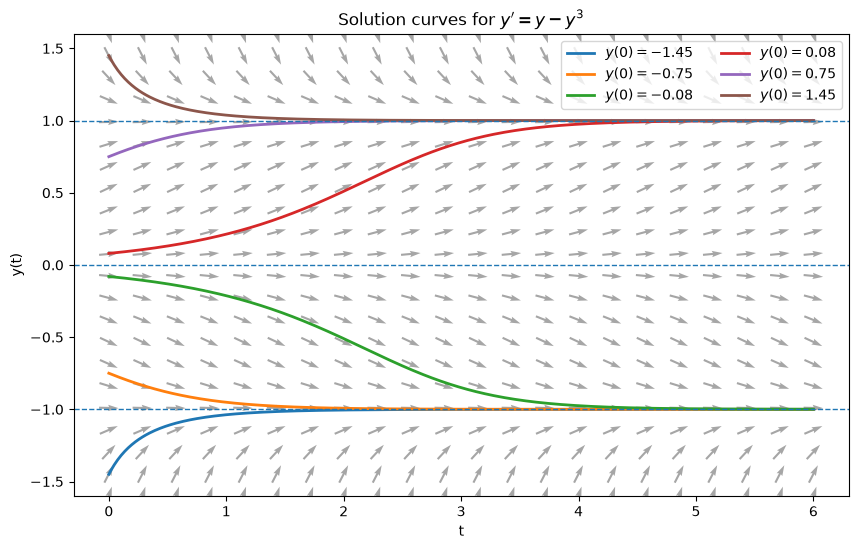

In [6]:
initial_values = [-1.45, -0.75, -0.08, 0.08, 0.75, 1.45]
t_eval = np.linspace(0, 6, 400)

fig, ax = plt.subplots(figsize=(10, 6))

# Direction field in the background.
t_grid = np.linspace(0, 6, 22)
y_grid = np.linspace(-1.6, 1.6, 22)
T, Y = np.meshgrid(t_grid, y_grid)
S = f(T, Y)
length = np.sqrt(1 + S**2)
ax.quiver(T, Y, 1 / length, S / length, angles="xy", pivot="mid", alpha=0.35)

for y0 in initial_values:
    sol = solve_ivp(
        f,
        (0, 6),
        [y0],
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11,
    )
    ax.plot(sol.t, sol.y[0], linewidth=2, label=fr"$y(0)={y0}$")

for c in equilibria:
    ax.axhline(c, linestyle="--", linewidth=1)

ax.set_xlabel("t")
ax.set_ylabel("y(t)")
ax.set_title(r"Solution curves for $y'=y-y^3$")
ax.set_ylim(-1.6, 1.6)
ax.legend(ncol=2)
plt.show()

## 5. Stable/unstable sets and the manifold idea

For this scalar equation, the phase space is only one-dimensional.

- Every initial value $y_0>0$ approaches $+1$, so $(0,\infty)$ is the basin of attraction of $+1$.
- Every initial value $y_0<0$ approaches $-1$, so $( -\infty,0)$ is the basin of attraction of $-1$.
- The equilibrium $0$ repels nearby points forward in time.
- Points with $-1<y_0<1$ approach $0$ when time is run backward, forming the one-dimensional unstable set associated with $0$.

In higher-dimensional systems, the analogous invariant sets become **stable and unstable manifolds**. We will return to that geometry when we study systems of ODEs.

### Check your understanding

1. Why are the rows of this direction field identical from left to right?
2. What happens to a solution starting at $y(0)=0.2$?
3. What happens to a solution starting at $y(0)=-1.4$?
4. Why does a solution starting exactly at $y(0)=0$ remain there even though the equilibrium is unstable?

[← Module 3](README.md) · [Next: Euler's Method →](02_euler_method.ipynb)